In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import Literal
import streamlit as st


## Libs for Agents
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain.agents import create_agent
from langchain.tools import tool

C:\Users\Mahesh Yadav\AppData\Local\Temp\ipykernel_17536\2751417805.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import GoogleSerperAPIWrapper


In [3]:
class FlowState(BaseModel):
    question : str = Field(description="User Asked Question")
    category : Literal['coding', 'google_search','weather'] = Field(default="google_search")
    answer : str = Field(default="")
    


In [4]:
class QuestionCategory(BaseModel):
    category : Literal['coding', 'google_search','weather'] = Field(default="google_search",description = "Question Category")

In [8]:
llm = ChatGroq(model="openai/gpt-oss-120b")

In [23]:
### Define Your Agents -googleSearchAgents, weather agent
search = GoogleSerperAPIWrapper()
tools = [search.run]

google_agent = create_agent(
    model=llm,
    tools =tools,
    system_prompt="you are a agent and can search for any question on google"

)



from langchain.tools import tool
import requests

@tool
def get_weather(city: str):
    """Get real-time weather for a city."""
    
    url = "https://wttr.in/{city}?format=3".format(city=city)
    response = requests.get(url, timeout=10)
    return response.text

weather_agent = create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are a weather agent that provides real weather information."
)



In [ ]:
## I'll use Open-Meteo, which provides weather forecasts without requiring an 
## API key for ordinary non-commercial use.


import requests
from langchain.tools import tool
from langchain.agents import create_agent

@tool
def get_weather(city: str):
    """Get current weather and temperature for any city."""
    
    try:
        # Step 1: Find the city's latitude and longitude
        geo_url = "https://geocoding-api.open-meteo.com/v1/search"
        
        geo_response = requests.get(
            geo_url,
            params={"name": city, "count": 1, "language": "en"},
            timeout=10
        )
        geo_response.raise_for_status()
        geo_data = geo_response.json()

        if not geo_data.get("results"):
            return f"City '{city}' not found."

        place = geo_data["results"][0]
        latitude = place["latitude"]
        longitude = place["longitude"]
        city_name = place["name"]
        country = place.get("country", "")

        # Step 2: Get current weather
        weather_url = "https://api.open-meteo.com/v1/forecast"

        weather_response = requests.get(
            weather_url,
            params={
                "latitude": latitude,
                "longitude": longitude,
                "current": (
                    "temperature_2m,"
                    "relative_humidity_2m,"
                    "apparent_temperature,"
                    "precipitation,"
                    "weather_code,"
                    "wind_speed_10m"
                ),
                "timezone": "auto"
            },
            timeout=10
        )
        weather_response.raise_for_status()
        weather_data = weather_response.json()
        current = weather_data["current"]

        return (
            f"Current weather in {city_name}, {country}:\n"
            f"Temperature: {current['temperature_2m']}°C\n"
            f"Feels like: {current['apparent_temperature']}°C\n"
            f"Humidity: {current['relative_humidity_2m']}%\n"
            f"Precipitation: {current['precipitation']} mm\n"
            f"Wind speed: {current['wind_speed_10m']} km/h\n"
            f"Weather code: {current['weather_code']}\n"
            f"Observation time: {current['time']}"
        )

    except requests.RequestException as e:
        return f"Unable to fetch weather data: {e}"
    except (KeyError, ValueError) as e:
        return f"Unable to process weather data: {e}"


weather_agent = create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt=(
        "You are a weather assistant. Use get_weather to retrieve "
        "real weather data for the requested city. Never invent "
        "temperatures or claim that a forecast is current without data."
    )
)


In [7]:

def Check_question_category(state: FlowState) -> dict:
    st_llm = llm.with_structured_output(
        QuestionCategory,
        method="json_mode"
    )

    res = st_llm.invoke(
        f"""Classify this question into exactly one category:
        coding, google_search, or weather.

        Question: {state.question}

        Return JSON in this format:
        {{"category": "google_search"}}
        """
    )

    print("Detected category:", res.category)

    return {"category": res.category}


In [10]:
def route(state:FlowState) -> Literal['coding','google_search','weather']:
    return state.category

In [11]:
def coding_node(state:FlowState) -> FlowState:
    res = llm.invoke(f"You are a coding expert: {state.question}")
    state.answer = res.content
    return state


def weather_node(state:FlowState) -> FlowState:
    res = weather_agent.invoke({"messages":[{"role":"user","content":state.question}]})
    state.answer = res["messages"][-1].content
    return state

def google_search_node(state:FlowState) -> FlowState:
    res = google_agent.invoke({"messages":[{"role":"user","content":state.question}]})
    state.answer = res["messages"][-1].content
    return state

In [12]:
graph = StateGraph(FlowState)

graph.add_node("Check_question_category",Check_question_category)
graph.add_node("coding", coding_node)
graph.add_node("weather", weather_node)
graph.add_node("google_search", google_search_node)

graph.add_edge(START, "Check_question_category")
graph.add_conditional_edges("Check_question_category",route)
graph.add_edge("coding",END)
graph.add_edge("weather",END)
graph.add_edge("google_search", END)

graph = graph.compile()

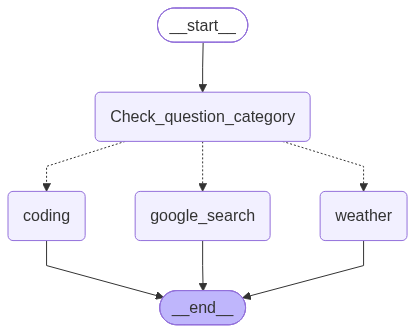

In [14]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [15]:
response = graph.invoke({
    "question": "What is the address of TechSimiplus?"
})

print("Category:", response["category"])
print("Answer:", response["answer"])

Detected category: google_search
Category: google_search
Answer: TechSimPlus (TechSimPlus Systems Private Limited) is located at:

**Plot No. 53, Sector C, Indrapuri (Raisen Road),  
Huzur, Bhopal – 462022, Madhya Pradesh, India**  

(Also commonly referenced as “2nd Floor, 53‑C, Near Yadav Tea Stall, Indrapuri, Bhopal 462021/462022”).


In [24]:
response = weather_agent.invoke({
    "messages": [
        {"role": "user", "content": "What is the current weather in Pune?"}
    ]
})

print(response["messages"][-1].content)

The current weather in **Pune** is **31 °C** with clear skies.
